# RQ19 — FINAL candidate prioritization

## Scientific objective

Convert the already completed PU benchmark into a **small, auditable set of unlabeled proteins prioritized for experimental characterization**.

This finalization notebook intentionally does **not** rebuild the Stage12 PU score table. It consumes the valid RQ19 cache produced by the completed v4 execution and recalculates only the final prioritization layer.

### Final analytical contract

Four evidence axes remain separate:

1. **Predictive robustness** — used to rank candidates.
2. **Generalization breadth** — R/S coverage and explicit R30/S30 availability/support.
3. **Orthogonal support** — Roxy physicochemical compatibility and T30 latent support.
4. **Sequence novelty** — distance from known P sequences using the existing 5-mer screening diagnostic.

No scalar combines these four axes.

Specifically, this notebook removes:

- `rs_consensus` from candidate ranking;
- `top5_frequency` from candidate ranking;
- the `0.75 predictive + 0.25 orthogonal` support-augmented score;
- the saturated predictive heatmap.

The final top-20 is therefore a **predictive top-20 with transparent orthogonal annotations**, not a hidden multi-objective scalar ranking.


## Why the predictive score changes

The previous score mixed predictive strength with R/S evidence availability. That made a protein evaluated under only one strict axis look artificially equivalent to a protein evaluated under both R30 and S30.

The final predictive score therefore contains only continuous predictive evidence:

\[
C_{\mathrm{pred}} =
\mathrm{mean}
\left(
\tilde p_{50},
\tilde p_{25},
C_{\mathrm{rep}},
C_{\mathrm{method}},
C_{\mathrm{learner}}
\right)
\]

where:

- \(\tilde p_{50}\): median U percentile across observations;
- \(\tilde p_{25}\): 25th percentile of U percentile, capturing repeated-evaluation robustness;
- \(C_{\mathrm{rep}}\): minimum support across T6/T30;
- \(C_{\mathrm{method}}\): minimum support across naive/BaggingPU;
- \(C_{\mathrm{learner}}\): minimum support across LR/XGB.

R/S breadth is reported separately and never converted into a penalty or reward.


In [1]:
from pathlib import Path
import hashlib
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 320)
pd.set_option("display.max_rows", 200)

TOP_N = 20
SHORTLIST_N = 100

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)

    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_candidates/rq19").is_dir()
            and (candidate / "data/processed/pnu_universes").is_dir()
            and (candidate / "data/representations").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate project root containing the completed RQ19 cache."
    )

ROOT = find_project_root()

RQ19_CACHE = ROOT / "results/analysis_candidates/rq19"
FINAL_CACHE = ROOT / "results/analysis_candidates/rq19_final"
FINAL_CACHE.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("INPUT CACHE:", RQ19_CACHE)
print("FINAL CACHE:", FINAL_CACHE)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
INPUT CACHE: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19
FINAL CACHE: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final


## 1. Real-cache preflight


In [2]:
CANDIDATE_CACHE = (
    RQ19_CACHE
    / "rq19_candidate_consensus_all.tsv"
)

if not CANDIDATE_CACHE.is_file():
    raise FileNotFoundError(
        "This finalization notebook requires the completed v4 candidate cache: "
        f"{CANDIDATE_CACHE}"
    )

candidate = pd.read_csv(
    CANDIDATE_CACHE,
    sep="\t",
    low_memory=False,
)

required_candidate_cols = {
    "sequence_key",
    "eligible_primary",
    "n_distinct_rs",
    "n_distinct_R",
    "n_distinct_S",
    "median_U_percentile",
    "q25_U_percentile",
    "top5_frequency",
    "top1_frequency",
    "representation_consensus",
    "method_consensus",
    "learner_consensus",
    "R30_median_percentile",
    "S30_median_percentile",
    "worst_rs_percentile",
}

missing = (
    required_candidate_cols
    - set(candidate.columns)
)

if missing:
    raise RuntimeError(
        "Completed RQ19 cache does not expose the required finalization columns: "
        f"{sorted(missing)}"
    )

# Normalize the persisted boolean safely.
if not pd.api.types.is_bool_dtype(
    candidate["eligible_primary"]
):
    candidate[
        "eligible_primary"
    ] = (
        candidate[
            "eligible_primary"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "1": True,
            "yes": True,
            "false": False,
            "0": False,
            "no": False,
        })
    )

if candidate[
    "eligible_primary"
].isna().any():
    raise RuntimeError(
        "Could not parse eligible_primary from the completed RQ19 cache."
    )

candidate[
    "sequence_key"
] = (
    candidate[
        "sequence_key"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

if candidate[
    "sequence_key"
].duplicated().any():
    raise RuntimeError(
        "Candidate cache contains duplicated sequence_key values."
    )

print(
    "REAL CACHE LOADED:",
    f"{len(candidate):,} candidate entities"
)
print(
    "Eligible under the frozen coverage contract:",
    f"{int(candidate['eligible_primary'].sum()):,}"
)


REAL CACHE LOADED: 209,972 candidate entities
Eligible under the frozen coverage contract: 101,370


## 2. Final predictive ranking — predictive evidence only


In [3]:
PREDICTIVE_COMPONENTS = [
    "median_U_percentile",
    "q25_U_percentile",
    "representation_consensus",
    "method_consensus",
    "learner_consensus",
]

for col in PREDICTIVE_COMPONENTS:
    candidate[col] = pd.to_numeric(
        candidate[col],
        errors="coerce",
    )

candidate[
    "predictive_core_score"
] = (
    candidate[
        PREDICTIVE_COMPONENTS
    ]
    .mean(
        axis=1,
        skipna=False,
    )
)

candidate[
    "predictive_core_min_component"
] = (
    candidate[
        PREDICTIVE_COMPONENTS
    ]
    .min(
        axis=1,
        skipna=False,
    )
)

eligible = (
    candidate[
        candidate[
            "eligible_primary"
        ]
    ]
    .dropna(
        subset=[
            "predictive_core_score",
            "predictive_core_min_component",
        ]
    )
    .copy()
)

eligible = eligible.sort_values(
    [
        "predictive_core_score",
        "predictive_core_min_component",
        "q25_U_percentile",
        "median_U_percentile",
    ],
    ascending=False,
    kind="stable",
).reset_index(drop=True)

eligible[
    "predictive_rank_final"
] = (
    np.arange(
        1,
        len(eligible) + 1,
    )
)

shortlist = (
    eligible.head(
        SHORTLIST_N
    )
    .copy()
)

top20 = (
    eligible.head(
        TOP_N
    )
    .copy()
)

display(
    eligible[
        [
            "predictive_core_score",
            "predictive_core_min_component",
            "median_U_percentile",
            "q25_U_percentile",
            "representation_consensus",
            "method_consensus",
            "learner_consensus",
        ]
    ].describe()
)

display(
    top20[
        [
            "predictive_rank_final",
            "sequence_key",
            "predictive_core_score",
            "predictive_core_min_component",
            "median_U_percentile",
            "q25_U_percentile",
            "representation_consensus",
            "method_consensus",
            "learner_consensus",
        ]
    ]
)


,predictive_core_score,predictive_core_min_component,median_U_percentile,q25_U_percentile,representation_consensus,method_consensus,learner_consensus
count,101370.000000,101370.000000,101370.000000,101370.000000,101370.000000,101370.000000,101370.000000
mean,0.436567,0.371844,0.500250,0.373828,0.414447,0.456328,0.437982
std,0.251798,0.252741,0.253876,0.253027,0.254215,0.258646,0.259577
min,0.002431,0.000073,0.003900,0.000080,0.000073,0.001570,0.000276
25%,0.225259,0.159226,0.289114,0.160747,0.201467,0.238799,0.217839
50%,0.408182,0.324521,0.488846,0.326921,0.379442,0.432634,0.411363
75%,0.628879,0.551854,0.705763,0.554571,0.605006,0.660739,0.641527
max,0.999981,0.999961,1.000000,0.999961,0.999971,1.000000,0.999974


,predictive_rank_final,sequence_key,predictive_core_score,predictive_core_min_component,median_U_percentile,q25_U_percentile,representation_consensus,method_consensus,learner_consensus
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,0.999981,0.999961,1.000000,0.999961,0.999971,1.000000,0.999974
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,0.999837,0.999796,0.999887,0.999796,0.999887,0.999820,0.999796
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0.999798,0.999709,0.999855,0.999709,0.999826,0.999775,0.999827
3,4,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,0.999795,0.999754,0.999829,0.999754,0.999814,0.999765,0.999814
4,5,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,0.999794,0.999700,0.999878,0.999700,0.999809,0.999818,0.999767
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,0.999768,0.999684,0.999824,0.999684,0.999810,0.999794,0.999729
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,0.999725,0.999640,0.999818,0.999640,0.999730,0.999766,0.999668
7,8,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,0.999674,0.999508,0.999796,0.999508,0.999678,0.999699,0.999689
8,9,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,0.999668,0.999434,0.999869,0.999461,0.999434,0.999767,0.999811
9,10,89bfdf1bd6c91ed798d242e7a0c13194a72d04b3557ea1...,0.999628,0.999464,0.999738,0.999464,0.999614,0.999709,0.999614


### Interpretation

`top5_frequency` and `top1_frequency` remain useful descriptive fields, but they do not determine the final rank because the previous execution showed strong saturation in the extreme candidate tail.

Likewise, no R/S variable enters `predictive_core_score`.


## 3. Predictive rank stability without R/S or orthogonal evidence


In [4]:
stability_rows = []

eligible_indexed = (
    eligible.set_index(
        "sequence_key"
    )
)

for dropped in PREDICTIVE_COMPONENTS:
    components = [
        c
        for c in PREDICTIVE_COMPONENTS
        if c != dropped
    ]

    score = (
        eligible_indexed[
            components
        ]
        .mean(
            axis=1,
            skipna=False,
        )
    )

    rank = score.rank(
        ascending=False,
        method="min",
    )

    for key in top20[
        "sequence_key"
    ]:
        stability_rows.append({
            "sequence_key": key,
            "dropped_component": dropped,
            "leave_one_out_score": (
                score.get(
                    key,
                    np.nan,
                )
            ),
            "leave_one_out_rank": (
                rank.get(
                    key,
                    np.nan,
                )
            ),
        })

rank_stability = pd.DataFrame(
    stability_rows
)

rank_stability_summary = (
    rank_stability.groupby(
        "sequence_key"
    )
    .agg(
        loo_best_rank=(
            "leave_one_out_rank",
            "min",
        ),
        loo_median_rank=(
            "leave_one_out_rank",
            "median",
        ),
        loo_worst_rank=(
            "leave_one_out_rank",
            "max",
        ),
        loo_rank_range=(
            "leave_one_out_rank",
            lambda x: x.max() - x.min(),
        ),
    )
    .reset_index()
)

top20 = top20.merge(
    rank_stability_summary,
    on="sequence_key",
    how="left",
    validate="one_to_one",
)

display(
    top20[
        [
            "predictive_rank_final",
            "sequence_key",
            "loo_best_rank",
            "loo_median_rank",
            "loo_worst_rank",
            "loo_rank_range",
        ]
    ]
)


,predictive_rank_final,sequence_key,loo_best_rank,loo_median_rank,loo_worst_rank,loo_rank_range
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,1.0,1.0,1.0,0.0
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,2.0,2.0,2.0,0.0
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,3.0,3.0,4.0,1.0
3,4,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,3.0,5.0,5.0,2.0
4,5,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,3.0,4.0,5.0,2.0
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,6.0,6.0,6.0,0.0
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,7.0,7.0,8.0,1.0
7,8,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,8.0,8.0,9.0,1.0
8,9,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,7.0,9.0,10.0,3.0
9,10,89bfdf1bd6c91ed798d242e7a0c13194a72d04b3557ea1...,10.0,11.0,11.0,1.0


## 4. Generalization breadth stays separate


In [5]:
for frame in [
    shortlist,
    top20,
]:
    frame[
        "rs_coverage_fraction"
    ] = (
        pd.to_numeric(
            frame[
                "n_distinct_rs"
            ],
            errors="coerce",
        )
        / 16.0
    )

    frame[
        "has_R30_support"
    ] = frame[
        "R30_median_percentile"
    ].notna()

    frame[
        "has_S30_support"
    ] = frame[
        "S30_median_percentile"
    ].notna()

    frame[
        "strict_R30_and_S30_support"
    ] = (
        frame[
            "has_R30_support"
        ]
        & frame[
            "has_S30_support"
        ]
    )

    frame[
        "strict_axis_evidence_class"
    ] = np.where(
        frame[
            "strict_R30_and_S30_support"
        ],
        "both_R30_and_S30_observed",
        np.where(
            frame[
                "has_R30_support"
            ]
            | frame[
                "has_S30_support"
            ],
            "one_strict_axis_observed",
            "neither_strict_axis_observed",
        ),
    )

strict_supported_top20 = (
    top20[
        top20[
            "strict_R30_and_S30_support"
        ]
    ]
    .copy()
)

display(
    top20[
        [
            "predictive_rank_final",
            "sequence_key",
            "n_distinct_rs",
            "rs_coverage_fraction",
            "R30_median_percentile",
            "S30_median_percentile",
            "strict_axis_evidence_class",
        ]
    ]
)

print(
    "Top-20 with evidence under BOTH R30 and S30:",
    f"{len(strict_supported_top20)}/{len(top20)}"
)


,predictive_rank_final,sequence_key,n_distinct_rs,rs_coverage_fraction,R30_median_percentile,S30_median_percentile,strict_axis_evidence_class
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,5,0.3125,0.999985,1.000000,both_R30_and_S30_observed
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,4,0.2500,0.999956,0.999971,both_R30_and_S30_observed
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,5,0.3125,0.999898,0.999898,both_R30_and_S30_observed
3,4,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,4,0.2500,0.999855,0.999773,both_R30_and_S30_observed
4,5,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,6,0.3750,NaN,0.999847,one_strict_axis_observed
5,6,3b4df2b6a240f1656a5aeb3b0d056ada8fc212dbbab11d...,4,0.2500,0.999796,0.999793,both_R30_and_S30_observed
6,7,d0796666c5dda8ba797fdf963cb5a7c4c03b6e05f5ba33...,7,0.4375,0.999811,0.999845,both_R30_and_S30_observed
7,8,7e61a47219beb87d20ad12108dfcaa65ab38d5d7b057a4...,5,0.3125,0.999840,NaN,one_strict_axis_observed
8,9,b2dd43fb0a7a7580661c67a4cb79a2d5ad67202827b13c...,4,0.2500,0.999825,0.999884,both_R30_and_S30_observed
9,10,89bfdf1bd6c91ed798d242e7a0c13194a72d04b3557ea1...,5,0.3125,0.999716,0.999811,both_R30_and_S30_observed


Top-20 with evidence under BOTH R30 and S30: 14/20


Missing R30 or S30 values mean **not evaluated in that strict outer-test axis**. They are not converted to zero and they are not imputed.

This is evidence availability, not a negative prediction.


## 5. Recover canonical biological identity


In [6]:
PNU_MASTER_PATH = (
    ROOT
    / "data/processed/pnu_universes/pnu_sequence_master.tsv.gz"
)

if not PNU_MASTER_PATH.is_file():
    raise FileNotFoundError(
        PNU_MASTER_PATH
    )

pnu_header = pd.read_csv(
    PNU_MASTER_PATH,
    sep="\t",
    compression="infer",
    nrows=0,
).columns.tolist()

identity_fields = [
    c
    for c in [
        "entity_id",
        "sequence",
        "sequence_sha256",
        "source_universe",
        "pnu_role",
        "sequence_state",
        "stratum",
        "canonical_target_class",
        "canonical_class_basis",
        "assigned_tier",
        "n_source_accessions",
        "source_accessions",
        "protein_names",
        "observed_evidence_states",
        "retrieval_scopes",
        "any_reviewed",
        "max_annotation_score",
    ]
    if c in pnu_header
]

required_identity = {
    "entity_id",
    "sequence",
    "sequence_sha256",
    "pnu_role",
    "sequence_state",
}

if not required_identity <= set(
    identity_fields
):
    raise RuntimeError(
        "Canonical P/N/U master is missing required identity fields."
    )

pnu_master = pd.read_csv(
    PNU_MASTER_PATH,
    sep="\t",
    compression="infer",
    dtype=str,
    usecols=identity_fields,
    low_memory=False,
).fillna("")

pnu_master[
    "sequence_sha256"
] = (
    pnu_master[
        "sequence_sha256"
    ]
    .str.strip()
    .str.lower()
)

pnu_master[
    "sequence"
] = (
    pnu_master[
        "sequence"
    ]
    .str.replace(
        r"\s+",
        "",
        regex=True,
    )
    .str.upper()
)

if pnu_master[
    "sequence_sha256"
].duplicated().any():
    raise RuntimeError(
        "Canonical P/N/U master violates exact-sequence uniqueness."
    )

shortlist_keys = set(
    shortlist[
        "sequence_key"
    ]
)

candidate_metadata = (
    pnu_master[
        pnu_master[
            "sequence_sha256"
        ].isin(
            shortlist_keys
        )
    ]
    .rename(
        columns={
            "sequence_sha256": "sequence_key",
            "entity_id": "canonical_entity_id",
        }
    )
    .copy()
)

mapped = set(
    candidate_metadata[
        "sequence_key"
    ]
)

missing_mapping = (
    shortlist_keys
    - mapped
)

if missing_mapping:
    raise RuntimeError(
        "Canonical identity mapping incomplete for final shortlist: "
        f"{len(missing_mapping)} missing."
    )

candidate_metadata[
    "sequence_uid"
] = candidate_metadata[
    "sequence_key"
]

candidate_metadata[
    "sequence_length"
] = (
    candidate_metadata[
        "sequence"
    ].str.len()
)

shortlist = shortlist.merge(
    candidate_metadata,
    on="sequence_key",
    how="left",
    validate="one_to_one",
)

top20 = top20.merge(
    candidate_metadata,
    on="sequence_key",
    how="left",
    validate="one_to_one",
)

positive_reference = (
    pnu_master[
        pnu_master[
            "pnu_role"
        ].str.upper().eq("P")
    ]
    .copy()
)

positive_keys = set(
    positive_reference[
        "sequence_sha256"
    ]
)

top20[
    "exact_sequence_key_seen_as_P"
] = (
    top20[
        "sequence_key"
    ].isin(
        positive_keys
    )
)

if top20[
    "exact_sequence_key_seen_as_P"
].any():
    raise RuntimeError(
        "Final top-20 contains an exact sequence already present in canonical P."
    )

display(
    top20[
        [
            "predictive_rank_final",
            "source_accessions",
            "protein_names",
            "sequence_length",
            "sequence_state",
            "strict_axis_evidence_class",
        ]
    ]
)


,predictive_rank_final,source_accessions,protein_names,sequence_length,sequence_state,strict_axis_evidence_class
0,1,R4TAX3,LysM domain-containing protein,362,U_other_unresolved,both_R30_and_S30_observed
1,2,Q4ZC50,ORF003,630,U_explicit,both_R30_and_S30_observed
2,3,A4ZFD3,Lyz,632,U_other_unresolved,both_R30_and_S30_observed
3,4,Q859A8,Gp50,278,U_other_unresolved,both_R30_and_S30_observed
4,5,D7NW66,Gp40,278,U_other_unresolved,one_strict_axis_observed
5,6,A0A7D5BIS8,L-alanoyl-D-glutamate peptidase protein,280,U_other_unresolved,both_R30_and_S30_observed
6,7,A0A288TY66,NlpC/P60 domain-containing protein,314,U_other_unresolved,both_R30_and_S30_observed
7,8,Q38323,NlpC/P60 domain-containing protein,259,U_other_unresolved,one_strict_axis_observed
8,9,G8FS22,Putative peptidase,275,U_other_unresolved,both_R30_and_S30_observed
9,10,U5PVY0,Lytic tail protein,246,U_other_unresolved,both_R30_and_S30_observed


## 6. Sequence novelty relative to canonical P


In [7]:
def kmer_set(sequence, k=5):
    seq = re.sub(
        r"\s+",
        "",
        str(sequence).upper(),
    )

    if len(seq) < k:
        return {seq} if seq else set()

    return {
        seq[i:i+k]
        for i in range(
            len(seq) - k + 1
        )
    }

def jaccard_sets(a, b):
    if not a or not b:
        return np.nan

    union = len(a | b)

    return (
        len(a & b) / union
        if union
        else np.nan
    )

P_kmers = [
    (
        row.sequence_sha256,
        kmer_set(
            row.sequence,
            5,
        ),
    )
    for row in positive_reference[
        [
            "sequence_sha256",
            "sequence",
        ]
    ].itertuples(
        index=False
    )
]

relatedness_rows = []

for row in top20.itertuples(
    index=False
):
    q = kmer_set(
        row.sequence,
        5,
    )

    best_key = None
    best_sim = -1.0

    for p_key, p_k in P_kmers:
        sim = jaccard_sets(
            q,
            p_k,
        )

        if (
            pd.notna(sim)
            and sim > best_sim
        ):
            best_sim = sim
            best_key = p_key

    relatedness_rows.append({
        "sequence_key": row.sequence_key,
        "nearest_P_5mer_jaccard": (
            best_sim
            if best_sim >= 0
            else np.nan
        ),
        "nearest_P_sequence_key_by_5mer": (
            best_key
        ),
    })

sequence_relatedness = pd.DataFrame(
    relatedness_rows
)

sequence_relatedness[
    "sequence_novelty"
] = (
    1.0
    - sequence_relatedness[
        "nearest_P_5mer_jaccard"
    ]
)

top20 = top20.merge(
    sequence_relatedness,
    on="sequence_key",
    how="left",
    validate="one_to_one",
)

display(
    top20[
        [
            "predictive_rank_final",
            "source_accessions",
            "nearest_P_5mer_jaccard",
            "sequence_novelty",
        ]
    ]
)


,predictive_rank_final,source_accessions,nearest_P_5mer_jaccard,sequence_novelty
0,1,R4TAX3,0.919571,0.080429
1,2,Q4ZC50,0.162725,0.837275
2,3,A4ZFD3,0.968652,0.031348
3,4,Q859A8,0.278689,0.721311
4,5,D7NW66,0.122984,0.877016
5,6,A0A7D5BIS8,0.360294,0.639706
6,7,A0A288TY66,0.907692,0.092308
7,8,Q38323,0.821429,0.178571
8,9,G8FS22,0.963768,0.036232
9,10,U5PVY0,0.819549,0.180451


`sequence_novelty = 1 - 5-mer Jaccard` is only a screening axis.

It is **not** sequence identity, evolutionary distance, or a homology estimate.


## 7. Frozen Roxy-48 and T30-640 contracts


In [8]:
REP_REGISTRY_PATH = (
    ROOT
    / "config/representation_registry/representation_registry.tsv"
)

if not REP_REGISTRY_PATH.is_file():
    raise FileNotFoundError(
        REP_REGISTRY_PATH
    )

rep_registry = pd.read_csv(
    REP_REGISTRY_PATH,
    sep="\t",
    dtype=str,
    low_memory=False,
).fillna("")

required_registry = {
    "representation_id",
    "status",
}

if not required_registry <= set(
    rep_registry.columns
):
    raise RuntimeError(
        "Representation registry does not satisfy the Stage12A minimum contract."
    )

def registry_ready_row(rep_id):
    rows = rep_registry[
        rep_registry[
            "representation_id"
        ].eq(
            rep_id
        )
    ]

    if len(rows) != 1:
        raise RuntimeError(
            f"Expected exactly one registry row for {rep_id}; found {len(rows)}."
        )

    row = rows.iloc[0].copy()

    if str(
        row[
            "status"
        ]
    ).strip().upper() != "READY":
        raise RuntimeError(
            f"{rep_id} is not READY."
        )

    return row

def resolve_representation_path(
    row,
    fallback,
):
    raw = str(
        row.get(
            "file_path",
            "",
        )
    ).strip()

    if raw:
        path = Path(
            raw
        ).expanduser()

        if not path.is_absolute():
            path = ROOT / path
    else:
        path = Path(
            fallback
        )

    if not path.is_file():
        raise FileNotFoundError(
            path
        )

    return path.resolve()

def table_columns(path):
    path = Path(path)

    if path.suffix.lower() == ".parquet":
        import pyarrow.parquet as pq

        return list(
            pq.ParquetFile(
                path
            ).schema_arrow.names
        )

    if path.suffix.lower() in {
        ".tsv",
        ".txt",
        ".gz",
    }:
        return pd.read_csv(
            path,
            sep="\t",
            compression="infer",
            nrows=0,
        ).columns.tolist()

    if path.suffix.lower() == ".csv":
        return pd.read_csv(
            path,
            nrows=0,
        ).columns.tolist()

    raise RuntimeError(
        f"Unsupported representation table: {path}"
    )

def read_subset(
    path,
    columns,
    keys,
):
    path = Path(path)

    if path.suffix.lower() == ".parquet":
        try:
            frame = pd.read_parquet(
                path,
                columns=columns,
                filters=[
                    (
                        "sequence_uid",
                        "in",
                        list(keys),
                    )
                ],
            )
        except Exception:
            frame = pd.read_parquet(
                path,
                columns=columns,
            )

            frame = frame[
                frame[
                    "sequence_uid"
                ]
                .astype(str)
                .isin(
                    set(keys)
                )
            ].copy()

        return frame

    if path.suffix.lower() in {
        ".tsv",
        ".txt",
        ".gz",
    }:
        frame = pd.read_csv(
            path,
            sep="\t",
            compression="infer",
            usecols=columns,
            low_memory=False,
        )
    elif path.suffix.lower() == ".csv":
        frame = pd.read_csv(
            path,
            usecols=columns,
            low_memory=False,
        )
    else:
        raise RuntimeError(
            f"Unsupported representation table: {path}"
        )

    return frame[
        frame[
            "sequence_uid"
        ]
        .astype(str)
        .isin(
            set(keys)
        )
    ].copy()

roxy_row = registry_ready_row(
    "roxy_48"
)

t30_row = registry_ready_row(
    "esm2_t30_150m"
)

ROXY_SCHEMA_PATH = (
    ROOT
    / "data/representations/roxy_characterization/descriptor_schema.tsv"
)

roxy_schema = pd.read_csv(
    ROXY_SCHEMA_PATH,
    sep="\t",
    dtype=str,
).fillna("")

if "feature" not in roxy_schema.columns:
    raise RuntimeError(
        "Roxy descriptor_schema.tsv lacks feature column."
    )

if "feature_order" in roxy_schema.columns:
    roxy_schema[
        "_order"
    ] = pd.to_numeric(
        roxy_schema[
            "feature_order"
        ],
        errors="raise",
    )

    roxy_schema = roxy_schema.sort_values(
        "_order",
        kind="stable",
    )

ROXY_FEATURES = (
    roxy_schema[
        "feature"
    ]
    .astype(str)
    .tolist()
)

if (
    len(ROXY_FEATURES) != 48
    or len(set(ROXY_FEATURES)) != 48
):
    raise RuntimeError(
        "Roxy contract failure: expected exactly 48 unique descriptors."
    )

ROXY_PATH = resolve_representation_path(
    roxy_row,
    ROOT
    / "data/representations/roxy_characterization/characterization_48.parquet",
)

T30_PATH = resolve_representation_path(
    t30_row,
    ROOT
    / "data/representations/sylphy_embeddings/models/"
    "facebook_esm2_t30_150m_ur50d/"
    "embeddings_last_mean_fp32.parquet",
)

roxy_cols = table_columns(
    ROXY_PATH
)

if any(
    c not in roxy_cols
    for c in [
        "sequence_uid",
        *ROXY_FEATURES,
    ]
):
    raise RuntimeError(
        "Roxy artifact does not contain the frozen 48-descriptor contract."
    )

t30_cols = table_columns(
    T30_PATH
)

pairs = []

for col in t30_cols:
    m = re.fullmatch(
        r"p_(\d+)",
        str(col),
    )

    if m:
        pairs.append(
            (
                int(
                    m.group(1)
                ),
                str(col),
            )
        )

pairs = sorted(
    pairs
)

T30_FEATURES = [
    c
    for _,
    c in pairs
]

T30_INDEX = [
    i
    for i,
    _ in pairs
]

if (
    len(T30_FEATURES) != 640
    or T30_INDEX != list(
        range(640)
    )
):
    raise RuntimeError(
        "T30 contract failure: expected exactly p_0...p_639."
    )

print(
    "Roxy scientific features:",
    len(ROXY_FEATURES),
)
print(
    "T30 scientific dimensions:",
    len(T30_FEATURES),
)


Roxy scientific features: 48
T30 scientific dimensions: 640


## 8. Orthogonal support — reported separately, never re-ranked


In [9]:
required_rep_keys = (
    set(
        shortlist[
            "sequence_key"
        ]
    )
    | positive_keys
)

roxy = read_subset(
    ROXY_PATH,
    [
        "sequence_uid",
        *ROXY_FEATURES,
    ],
    required_rep_keys,
)

t30 = read_subset(
    T30_PATH,
    [
        "sequence_uid",
        *T30_FEATURES,
    ],
    required_rep_keys,
)

for frame, name in [
    (roxy, "roxy_48"),
    (t30, "esm2_t30_150m"),
]:
    frame[
        "sequence_uid"
    ] = (
        frame[
            "sequence_uid"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    if frame[
        "sequence_uid"
    ].duplicated().any():
        raise RuntimeError(
            f"{name} contains duplicated sequence_uid rows."
        )

    frame[
        "sequence_key"
    ] = frame[
        "sequence_uid"
    ]

shortlist_keys = set(
    shortlist[
        "sequence_key"
    ]
)

if not shortlist_keys <= set(
    roxy[
        "sequence_key"
    ]
):
    raise RuntimeError(
        "Roxy coverage incomplete for final top-100."
    )

if not shortlist_keys <= set(
    t30[
        "sequence_key"
    ]
):
    raise RuntimeError(
        "T30 coverage incomplete for final top-100."
    )

# ---------- Roxy ----------
P_roxy = roxy[
    roxy[
        "sequence_key"
    ].isin(
        positive_keys
    )
].copy()

C_roxy = roxy[
    roxy[
        "sequence_key"
    ].isin(
        shortlist_keys
    )
].copy()

Pmat = (
    P_roxy[
        ROXY_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .astype("float64")
)

Cmat = (
    C_roxy[
        ROXY_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .astype("float64")
)

if (
    Pmat.shape[1] != 48
    or Cmat.shape[1] != 48
):
    raise RuntimeError(
        "Roxy support did not use exactly 48 descriptors."
    )

med = Pmat.median(axis=0)
q25 = Pmat.quantile(0.25, axis=0)
q75 = Pmat.quantile(0.75, axis=0)

iqr = (
    q75 - q25
).replace(
    0,
    np.nan,
)

low = Pmat.quantile(
    0.025,
    axis=0,
)

high = Pmat.quantile(
    0.975,
    axis=0,
)

robust_z = (
    Cmat - med
).abs().divide(
    iqr,
    axis=1,
)

within = (
    Cmat.ge(
        low,
        axis=1,
    )
    & Cmat.le(
        high,
        axis=1,
    )
)

roxy_support = pd.DataFrame({
    "sequence_key": (
        C_roxy[
            "sequence_key"
        ].to_numpy()
    ),
    "roxy_fraction_within_P_95pct_ranges": (
        within.mean(
            axis=1,
            skipna=True,
        ).to_numpy()
    ),
    "roxy_median_abs_robust_z_to_P": (
        robust_z.median(
            axis=1,
            skipna=True,
        ).to_numpy()
    ),
})

roxy_support[
    "roxy_compatibility_support"
] = (
    roxy_support[
        "roxy_fraction_within_P_95pct_ranges"
    ]
    * (
        1.0
        / (
            1.0
            + roxy_support[
                "roxy_median_abs_robust_z_to_P"
            ]
        )
    )
)

# ---------- T30 ----------
P_t30 = t30[
    t30[
        "sequence_key"
    ].isin(
        positive_keys
    )
].copy()

C_t30 = t30[
    t30[
        "sequence_key"
    ].isin(
        shortlist_keys
    )
].copy()

Pmat = (
    P_t30[
        T30_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .to_numpy(
        dtype=np.float64
    )
)

Cmat = (
    C_t30[
        T30_FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .to_numpy(
        dtype=np.float64
    )
)

if (
    Pmat.shape[1] != 640
    or Cmat.shape[1] != 640
):
    raise RuntimeError(
        "T30 support did not use exactly 640 dimensions."
    )

def l2_normalize(X):
    norm = np.linalg.norm(
        X,
        axis=1,
        keepdims=True,
    )

    return np.divide(
        X,
        norm,
        out=np.zeros_like(
            X,
            dtype=float,
        ),
        where=norm > 0,
    )

Pn = l2_normalize(
    Pmat
)

Cn = l2_normalize(
    Cmat
)

centroid = Pn.mean(
    axis=0
)

centroid = (
    centroid
    / np.linalg.norm(
        centroid
    )
)

cosine_to_centroid = (
    Cn @ centroid
)

k = min(
    5,
    len(Pn),
)

mean_topk = []

for row in Cn:
    sim = Pn @ row

    idx = np.argpartition(
        sim,
        -k,
    )[-k:]

    mean_topk.append(
        float(
            np.mean(
                sim[idx]
            )
        )
    )

P_centroid_sim = (
    Pn @ centroid
)

latent_percentile = (
    np.searchsorted(
        np.sort(
            P_centroid_sim
        ),
        cosine_to_centroid,
        side="right",
    )
    / len(
        P_centroid_sim
    )
)

t30_support = pd.DataFrame({
    "sequence_key": (
        C_t30[
            "sequence_key"
        ].to_numpy()
    ),
    "T30_cosine_to_P_centroid": (
        cosine_to_centroid
    ),
    "T30_mean_top5_P_cosine": (
        np.asarray(
            mean_topk
        )
    ),
    "T30_centroid_similarity_percentile_vs_P": (
        latent_percentile
    ),
})

t30_support[
    "T30_latent_support"
] = (
    0.5
    * t30_support[
        "T30_centroid_similarity_percentile_vs_P"
    ]
    + 0.5
    * (
        (
            t30_support[
                "T30_mean_top5_P_cosine"
            ]
            + 1.0
        )
        / 2.0
    )
)

shortlist = (
    shortlist
    .merge(
        roxy_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
    .merge(
        t30_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

top20 = (
    top20
    .merge(
        roxy_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
    .merge(
        t30_support,
        on="sequence_key",
        how="left",
        validate="one_to_one",
    )
)

display(
    top20[
        [
            "predictive_rank_final",
            "source_accessions",
            "roxy_compatibility_support",
            "T30_latent_support",
        ]
    ]
)


,predictive_rank_final,source_accessions,roxy_compatibility_support,T30_latent_support
0,1,R4TAX3,0.620295,0.885165
1,2,Q4ZC50,0.565273,0.811575
2,3,A4ZFD3,0.620073,0.874753
3,4,Q859A8,0.448258,0.640117
4,5,D7NW66,0.652990,0.793978
5,6,A0A7D5BIS8,0.556216,0.693861
6,7,A0A288TY66,0.598332,0.677226
7,8,Q38323,0.544968,0.716870
8,9,G8FS22,0.709732,0.889904
9,10,U5PVY0,0.501599,0.528327


## 9. Final evidence panel — no hidden scalar


In [10]:
final_panel = top20.copy()

final_panel[
    "presentation_status"
] = (
    "prioritized_for_experimental_characterization"
)

final_panel[
    "strict_axis_panel"
] = np.where(
    final_panel[
        "strict_R30_and_S30_support"
    ],
    "strict_axis_supported",
    "predictive_candidate_partial_strict_axis_evidence",
)

final_columns = [
    c
    for c in [
        "predictive_rank_final",
        "sequence_key",
        "sequence_uid",
        "canonical_entity_id",
        "source_accessions",
        "protein_names",
        "sequence",
        "sequence_length",
        "source_universe",
        "pnu_role",
        "sequence_state",
        "stratum",
        "presentation_status",
        "strict_axis_panel",
        "exact_sequence_key_seen_as_P",
        "predictive_core_score",
        "predictive_core_min_component",
        "median_U_percentile",
        "q25_U_percentile",
        "top5_frequency",
        "top1_frequency",
        "representation_consensus",
        "method_consensus",
        "learner_consensus",
        "loo_best_rank",
        "loo_median_rank",
        "loo_worst_rank",
        "loo_rank_range",
        "n_distinct_rs",
        "rs_coverage_fraction",
        "R30_median_percentile",
        "S30_median_percentile",
        "has_R30_support",
        "has_S30_support",
        "strict_R30_and_S30_support",
        "worst_rs_percentile",
        "roxy_fraction_within_P_95pct_ranges",
        "roxy_median_abs_robust_z_to_P",
        "roxy_compatibility_support",
        "T30_cosine_to_P_centroid",
        "T30_mean_top5_P_cosine",
        "T30_centroid_similarity_percentile_vs_P",
        "T30_latent_support",
        "nearest_P_5mer_jaccard",
        "sequence_novelty",
        "nearest_P_sequence_key_by_5mer",
    ]
    if c in final_panel.columns
]

final_panel = (
    final_panel[
        final_columns
    ]
    .sort_values(
        "predictive_rank_final"
    )
    .reset_index(drop=True)
)

strict_supported_panel = (
    final_panel[
        final_panel[
            "strict_R30_and_S30_support"
        ]
    ]
    .copy()
)

display(final_panel)


,predictive_rank_final,sequence_key,sequence_uid,canonical_entity_id,source_accessions,protein_names,sequence,sequence_length,source_universe,pnu_role,sequence_state,stratum,presentation_status,strict_axis_panel,exact_sequence_key_seen_as_P,predictive_core_score,predictive_core_min_component,median_U_percentile,q25_U_percentile,top5_frequency,top1_frequency,representation_consensus,method_consensus,learner_consensus,loo_best_rank,loo_median_rank,loo_worst_rank,loo_rank_range,n_distinct_rs,rs_coverage_fraction,R30_median_percentile,S30_median_percentile,has_R30_support,has_S30_support,strict_R30_and_S30_support,worst_rs_percentile,roxy_fraction_within_P_95pct_ranges,roxy_median_abs_robust_z_to_P,roxy_compatibility_support,T30_cosine_to_P_centroid,T30_mean_top5_P_cosine,T30_centroid_similarity_percentile_vs_P,T30_latent_support,nearest_P_5mer_jaccard,sequence_novelty,nearest_P_sequence_key_by_5mer
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,UNIPROTSEQ_9a7fc10ce8f1e73a75b03da3,R4TAX3,LysM domain-containing protein,MPNGPQLYPKADARTQFYGGKFNGSLMEVNVGVIHTTEGTSFPDYG...,362,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999981,0.999961,1.000000,0.999961,1.0,1.0,0.999971,1.000000,0.999974,1.0,1.0,1.0,0.0,5,0.3125,0.999985,1.000000,True,True,True,0.999980,1.000000,0.612137,0.620295,0.984533,0.999670,0.770495,0.885165,0.919571,0.080429,4f682eb5fc2061fee7c20f74cdb45d25c3b37a657c7684...
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,UNIPROTSEQ_b10be3e825a719cd3a317155,Q4ZC50,ORF003,MGLPNPRVRKPTASEVAAWAKSNIGKRVDVDGYRGAQCWDTPNFIF...,630,uniprot_background,U,U_explicit,u_low_information,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999837,0.999796,0.999887,0.999796,1.0,1.0,0.999887,0.999820,0.999796,2.0,2.0,2.0,0.0,4,0.2500,0.999956,0.999971,True,True,True,0.999852,0.937500,0.658490,0.565273,0.981321,0.996632,0.624833,0.811575,0.162725,0.837275,50442f027d5cd0cc3646dca73632ad3309ee202ad8b238...
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,UNIPROTSEQ_0ecc91724a5ec4f0a20c95f5,A4ZFD3,Lyz,MGLPNPKNRKPTASEVVEWALYIAKNKIAIDVPGSGMGAQCWDLPN...,632,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999798,0.999709,0.999855,0.999709,1.0,1.0,0.999826,0.999775,0.999827,3.0,3.0,4.0,1.0,5,0.3125,0.999898,0.999898,True,True,True,0.999813,0.958333,0.545516,0.620073,0.984003,0.999945,0.749534,0.874753,0.968652,0.031348,b8de5422cfa97fd4c7bae89e2306a62ef97a1d77434f11...
3,4,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,UNIPROTSEQ_c863cc7d8407891d4a2a12bb,Q859A8,Gp50,MSIAKLVEIAKGEVGYHEGRSGGHWNNHQKYSPAVPGLEWSQNQAW...,278,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999795,0.999754,0.999829,0.999754,1.0,1.0,0.999814,0.999765,0.999814,3.0,5.0,5.0,2.0,4,0.2500,0.999855,0.999773,True,True,True,0.999773,0.833333,0.859049,0.448258,0.968327,0.995942,0.282263,0.640117,0.278689,0.721311,daa30e0ded399c841812b4f110c1c6c0d74e51876e4c65...
4,5,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,UNIPROTSEQ_46535c19fce21c85f3b89d31,D7NW66,Gp40,MDSPSRPGRVVWHTTESGAGNAAFDAVGKYLRQISAEPHVLYDPTT...,278,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,predictive_candidate_partial_strict_axis_evidence,False,0.999794,0.999700,0.999878,0.999700,1.0,1.0,0.999809,0.999818,0.999767,3.0,4.0,5.0,2.0,6,0.3750,NaN,0.999847,False,True,False,0.999821,1.000000,0.531417,0.652990,0.980456,0.992324,0.591793,0.793978,0.122984,0.877016,0eb28ed0370d62b8cfa1af1b140d7cc7a38b16b978c88f...
5,6,3b4df2b6a240

The top-20 remains ordered **only by predictive robustness**.

`strict_supported_panel` is not a re-ranking. It is the subset of the predictive top-20 for which both R30 and S30 evidence are actually available.


## 10. Informative evidence heatmap


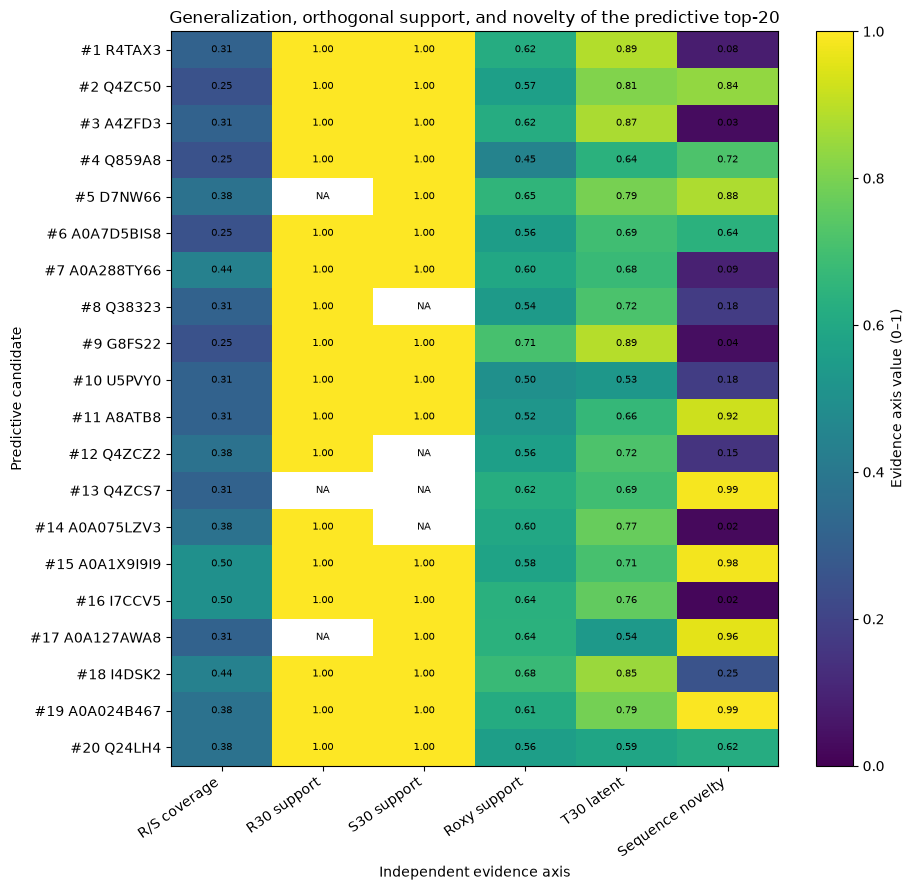

In [11]:
heatmap = final_panel[
    [
        "rs_coverage_fraction",
        "R30_median_percentile",
        "S30_median_percentile",
        "roxy_compatibility_support",
        "T30_latent_support",
        "sequence_novelty",
    ]
].copy()

heatmap.columns = [
    "R/S coverage",
    "R30 support",
    "S30 support",
    "Roxy support",
    "T30 latent",
    "Sequence novelty",
]

labels = []

for row in final_panel.itertuples(
    index=False
):
    accession = str(
        getattr(
            row,
            "source_accessions",
            "",
        )
    ).split(";")[0].strip()

    if not accession:
        accession = str(
            row.sequence_key
        )[:8]

    labels.append(
        f"#{int(row.predictive_rank_final)} {accession}"
    )

fig, ax = plt.subplots(
    figsize=(9.5, 9.0)
)

data = heatmap.to_numpy(
    dtype=float
)

masked = np.ma.masked_invalid(
    data
)

im = ax.imshow(
    masked,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(
    np.arange(
        len(
            heatmap.columns
        )
    )
)

ax.set_xticklabels(
    heatmap.columns,
    rotation=35,
    ha="right",
)

ax.set_yticks(
    np.arange(
        len(labels)
    )
)

ax.set_yticklabels(
    labels
)

ax.set_xlabel(
    "Independent evidence axis"
)

ax.set_ylabel(
    "Predictive candidate"
)

ax.set_title(
    "Generalization, orthogonal support, and novelty of the predictive top-20"
)

for i in range(
    data.shape[0]
):
    for j in range(
        data.shape[1]
    ):
        value = data[i, j]

        text = (
            "NA"
            if not np.isfinite(
                value
            )
            else f"{value:.2f}"
        )

        ax.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=7,
        )

fig.colorbar(
    im,
    ax=ax,
    label="Evidence axis value (0–1)",
)

plt.tight_layout()
plt.show()


The heatmap deliberately excludes the variables used to select the top-20.

Therefore it is **not circular**: rows are selected by predictive robustness, while the displayed columns show independent generalization breadth, orthogonal support, and sequence novelty.

`NA` means the candidate was not evaluated in that strict axis.


## 11. Compact RQ19 evidence summary


In [12]:
summary = pd.DataFrame(
    [
        {
            "eligible_candidates": len(
                eligible
            ),
            "top20_min_predictive_core": (
                final_panel[
                    "predictive_core_score"
                ].min()
            ),
            "top20_median_predictive_core": (
                final_panel[
                    "predictive_core_score"
                ].median()
            ),
            "top20_median_q25_percentile": (
                final_panel[
                    "q25_U_percentile"
                ].median()
            ),
            "top20_fraction_top5_every_observation": (
                final_panel[
                    "top5_frequency"
                ].eq(1.0).mean()
            ),
            "top20_fraction_both_R30_S30_observed": (
                final_panel[
                    "strict_R30_and_S30_support"
                ].mean()
            ),
            "top20_median_rs_cells": (
                final_panel[
                    "n_distinct_rs"
                ].median()
            ),
            "top20_median_roxy_support": (
                final_panel[
                    "roxy_compatibility_support"
                ].median()
            ),
            "top20_median_T30_latent_support": (
                final_panel[
                    "T30_latent_support"
                ].median()
            ),
            "top20_median_sequence_novelty": (
                final_panel[
                    "sequence_novelty"
                ].median()
            ),
            "top20_exact_P_identity_fraction": (
                final_panel[
                    "exact_sequence_key_seen_as_P"
                ].mean()
                if "exact_sequence_key_seen_as_P"
                in final_panel.columns
                else 0.0
            ),
            "strict_axis_supported_top20_n": len(
                strict_supported_panel
            ),
        }
    ]
)

display(summary)


,eligible_candidates,top20_min_predictive_core,top20_median_predictive_core,top20_median_q25_percentile,top20_fraction_top5_every_observation,top20_fraction_both_R30_S30_observed,top20_median_rs_cells,top20_median_roxy_support,top20_median_T30_latent_support,top20_median_sequence_novelty,top20_exact_P_identity_fraction,strict_axis_supported_top20_n
0,101370,0.999225,0.999626,0.999431,1.0,0.7,5.0,0.599448,0.719286,0.437517,0.0,14


## Final interpretation guardrails

RQ19 can support the following statement:

> A subset of unlabeled proteins remains consistently candidate-like across independent pretrained representations, PU formulations, and downstream learners. The strongest predictive candidates can then be characterized independently by their R/S evaluation breadth, physicochemical compatibility, latent representation support, and sequence novelty, providing a transparent basis for experimental prioritization.

RQ19 does **not** support:

- a calibrated probability that a candidate is lytic;
- a claim that Roxy/T30 support validates function;
- treating missing R30/S30 evaluation as negative evidence;
- a single universal multi-evidence score;
- mechanism assignment;
- biological validation without experiment.


## 12. Export final RQ19 tables


In [13]:
EXPORTS = {
    FINAL_CACHE
    / "rq19_final_predictive_ranked_all.tsv":
        eligible,
    FINAL_CACHE
    / "rq19_final_predictive_shortlist_top100.tsv":
        shortlist,
    FINAL_CACHE
    / "rq19_final_predictive_rank_stability.tsv":
        rank_stability,
    FINAL_CACHE
    / "rq19_final_top20_evidence_panel.tsv":
        final_panel,
    FINAL_CACHE
    / "rq19_final_strict_axis_supported_subset.tsv":
        strict_supported_panel,
    FINAL_CACHE
    / "rq19_final_sequence_relatedness.tsv":
        sequence_relatedness,
    FINAL_CACHE
    / "rq19_final_roxy_support.tsv":
        roxy_support,
    FINAL_CACHE
    / "rq19_final_T30_latent_support.tsv":
        t30_support,
    FINAL_CACHE
    / "rq19_final_summary.tsv":
        summary,
}

for path, frame in EXPORTS.items():
    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print(
    "Saved final RQ19 tables:"
)

for path in EXPORTS:
    print(" ", path)


Saved final RQ19 tables:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final/rq19_final_predictive_ranked_all.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final/rq19_final_predictive_shortlist_top100.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final/rq19_final_predictive_rank_stability.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final/rq19_final_top20_evidence_panel.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final/rq19_final_strict_axis_supported_subset.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_candidates/rq19_final/rq19_final_sequence_relatedness.tsv
  /home/david/Desktop/co

## Closure criterion

If this notebook executes without errors on the real project:

- the candidate rank is based only on predictive evidence;
- R/S is an independent coverage/support axis;
- Roxy and T30 are independent orthogonal support axes;
- sequence novelty is independent;
- no support-augmented scalar exists;
- no saturated predictive heatmap remains.

At that point RQ19 is finished and the workflow moves to **RQ20 — deployment/generalization-regime synthesis**.
